# Soluzioni — Lezione 5: L'AI come assistente, k-means
[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/solutions/05_ai_assistente_kmeans_soluzioni.ipynb)

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = list(famiglie["forma"])
FAMIGLIA_DI = dict(zip(famiglie["forma"], famiglie["famiglia"]))
RISULTATI = Path("risultati")
RISULTATI.mkdir(exist_ok=True)

STOPWORDS = set()
for riga in (DATI / "stopwords_it.txt").read_text(encoding="utf-8").splitlines():
    if not riga.startswith("#"):
        STOPWORDS.update(riga.split())
STOPWORDS = sorted(STOPWORDS)

In [3]:
def leggi(percorso):
    """Restituisce (intestazione, testo): le righe che iniziano con # sono l'intestazione."""
    righe = percorso.read_text(encoding="utf-8").splitlines()
    intestazione = [r for r in righe if r.startswith("#")]
    testo = "\n".join(r for r in righe if not r.startswith("#"))
    return intestazione, testo

def parole(testo):
    return re.findall(r"\w+", testo.lower())

def conta_felici(testo):
    """Conta le parole felici confrontando PAROLE INTERE, non pezzi di parola."""
    return sum(p in FAMIGLIA_DI for p in parole(testo))

def rapporto(cartella):
    righe = []
    for percorso in sorted(cartella.glob("*.txt")):
        intestazione, testo = leggi(percorso)
        titolo_autore = intestazione[0].lstrip("# ").split(" — ")
        p = parole(testo)
        frasi = [f for f in re.split(r"[.!?]+", testo) if f.strip()]
        famiglie_presenti = Counter(FAMIGLIA_DI[x] for x in p if x in FAMIGLIA_DI)
        righe.append({
            "file": percorso.name,
            "titolo": titolo_autore[0],
            "autore": titolo_autore[-1],
            "parole": len(p),
            "parole_per_frase": round(len(p) / max(len(frasi), 1), 1),
            "felici_1000": round(conta_felici(testo) / len(p) * 1000, 2),
            "famiglia_prevalente": famiglie_presenti.most_common(1)[0][0] if famiglie_presenti else "",
        })
    return pd.DataFrame(righe)

## Esercizio 1 — Trova l'errore

In [4]:
def parole_piu_lunghe(testo, n=5):
    parole_testo = testo.split()
    parole_testo.sort(key=len)
    return parole_testo[:n]

frase = "La felicità, diceva il poeta, è un'attesa: la felicità è sempre domani."
print(parole_piu_lunghe(frase, 3))   # restituisce le più CORTE, e ripetute

['è', 'è', 'La']


Gli errori sono tre:
1. `sort(key=len)` ordina dalla più corta alla più lunga: servono le ultime, oppure `reverse=True`;
2. `split()` lascia la punteggiatura attaccata (*felicità,* è diversa da *felicità*);
3. non toglie le ripetizioni.

In [5]:
def parole_piu_lunghe(testo, n=5):
    """Restituisce le n parole più lunghe del testo, senza ripetizioni (a parità di lunghezza: ordine alfabetico)."""
    uniche = set(re.findall(r"\w+", testo.lower()))
    return sorted(uniche, key=lambda p: (-len(p), p))[:n]

assert parole_piu_lunghe("ciao bellissimo mondo", 1) == ["bellissimo"]
assert parole_piu_lunghe("felicità, felicità! gioia", 2) == ["felicità", "gioia"]
assert len(parole_piu_lunghe(frase, 10)) == len(set(parole_piu_lunghe(frase, 10)))
print("Test superati ✅", parole_piu_lunghe(frase, 3))

Test superati ✅ ['felicità', 'attesa', 'diceva']


**Prompt di correzione possibile:**
> Questa funzione Python dovrebbe restituire le n parole più lunghe di un testo, senza ripetizioni e senza punteggiatura.
> Con l'input `"La felicità, diceva il poeta..."` e n=3 mi restituisce `['è', 'è', 'La']`, cioè le più corte, con ripetizioni.
> Ecco il codice: [...]. Correggila, aggiungi due test con assert e spiegami in italiano che cosa sbagliava.

## Esercizio 2 — Estendere l'automazione

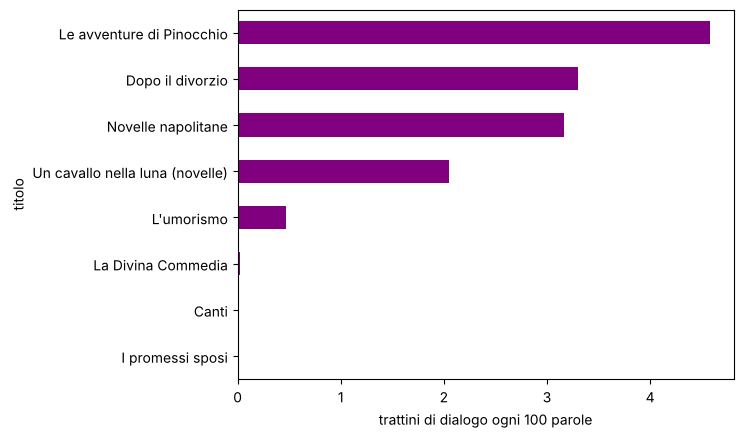

,titolo,parola_piu_frequente,dialogo_100
0,Le avventure di Pinocchio,pinocchio,4.58
1,La Divina Commedia,son,0.02
2,Dopo il divorzio,giovanna,3.30
3,Novelle napolitane,disse,3.16
4,Canti,vita,0.00
5,I promessi sposi,disse,0.00
6,Un cavallo nella luna (novelle),due,2.05
7,L'umorismo,umorismo,0.47


In [6]:
def rapporto_esteso(cartella):
    tab = rapporto(cartella)
    piu_frequenti, dialogo = [], []
    for nome in tab["file"]:
        _, testo = leggi(cartella / nome)
        p = parole(testo)
        contenuto = Counter(x for x in p if x not in STOPWORDS and len(x) > 2)
        piu_frequenti.append(contenuto.most_common(1)[0][0])
        dialogo.append(round(testo.count("—") / len(p) * 100, 2))
    tab["parola_piu_frequente"] = piu_frequenti
    tab["dialogo_100"] = dialogo
    return tab

tab = rapporto_esteso(DATI / "testi")
tab.to_csv(RISULTATI / "rapporto_testi_esteso.csv", index=False)
tab.set_index("titolo")["dialogo_100"].sort_values().plot(kind="barh", color="purple")
plt.xlabel("trattini di dialogo ogni 100 parole"); plt.show()
tab[["titolo", "parola_piu_frequente", "dialogo_100"]]

**Commento.** Il trattino misura bene il dialogo in Collodi, Deledda, Pirandello e Di Giacomo, ma Manzoni (in questa edizione)
usa le virgolette «» e Dante non usa trattini: lo stesso indicatore non è confrontabile tra edizioni diverse.

## Esercizio 3 — Un altro k

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
passaggi = pd.read_csv(DATI / "passaggi_autori.csv")
X = TfidfVectorizer(max_features=3000, min_df=3, stop_words=STOPWORDS).fit_transform(passaggi["testo"])
for k in [3, 8]:
    etichette = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    print(f"\n=== k = {k} ===")
    print(pd.crosstab(etichette, passaggi["autore"]))


=== k = 3 ===
autore  Collodi  Deledda  Di Giacomo  Manzoni  Pirandello
row_0                                                    
0             1        0         120      120         120
1             0      120           0        0           0
2           119        0           0        0           0

=== k = 8 ===
autore  Collodi  Deledda  Di Giacomo  Manzoni  Pirandello
row_0                                                    
0             1        0          91        1           8
1             4        1          18        2          59
2             0       25           4        2          14
3           114        0           0        0           0
4             0       92           0        0           0
5             1        1           3       37          11
6             0        0           0        0          27
7             0        1           4       78           1


**Commento.** Con k = 3 alcuni autori devono **condividere** un gruppo: il k-means unisce quelli che si somigliano di più nel
lessico. Con k = 8 alcuni autori vengono **divisi** in più gruppi, spesso per contenuto (personaggi diversi, ambientazioni,
dialogo vs narrazione). Il k "giusto" dipende dalla domanda: se cerchiamo autori, 5; se cerchiamo temi, forse di più.
L'algoritmo trova *una* struttura, non *la* struttura.